# Data preprocessing: making the SVR dataset ready for clean training

## Contents
1. Before: the raw dataset
2. The preprocessing process
3. After: the clean dataset
4. Before and after comparison
5. Ablation study: every step and its result
6. Overview samples: before and after
7. Re-transcription experiment and recovered files: the final results

Scope: the full SVR dataset, 6,522 audio files and 6,024 transcripts. This notebook shows the process that makes the data ready, the comparison between before and after with charts, and an ablation study that records each step with its result. Every number below is computed from the source files in this run.

New structure: the clean dataset now lives in dataset/train/, dataset/val/ and dataset/test/ in this repo. Each split holds its audio files plus labels.csv. File names are clean: customer state, 4 digit index, .wav only, for example calm_0001.wav. The rename map is rename_mapping.csv at the repo root. Every path in this notebook uses the new structure.

In [1]:
import json
import re
from pathlib import Path

import pandas as pd
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import Image, display

WS = Path("/home/hatch/workspace/ai-customer-support")
REPO = WS / "smart-voicemail-router"
PREPARED = WS / "dataset" / "prepared"
PREPROCESSED = WS / "dataset" / "preprocessed"
DATASET = REPO / "dataset"
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

def save_fig(fig, fname):
    path = FIGDIR / fname
    FigureCanvasAgg(fig).print_png(str(path))
    return path

def show(fname):
    display(Image(str(FIGDIR / fname)))

def bar(values, labels, title, ylabel, fname, color="#2f6fb2", horizontal=False):
    fig = Figure(figsize=(8, 4.6))
    ax = fig.add_subplot(111)
    if horizontal:
        ax.barh(labels, values, color=color)
        ax.set_title(title)
        ax.set_xlabel(ylabel)
    else:
        ax.bar(labels, values, color=color)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    save_fig(fig, fname)
    show(fname)

def grouped_bar(labels, before, after, title, ylabel, fname, before_label="before", after_label="after"):
    fig = Figure(figsize=(8, 4.2))
    ax = fig.add_subplot(111)
    x = list(range(len(labels)))
    w = 0.35
    ax.bar([i - w / 2 for i in x], before, width=w, color="#9aa5b1", label=before_label)
    ax.bar([i + w / 2 for i in x], after, width=w, color="#2f6fb2", label=after_label)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    save_fig(fig, fname)
    show(fname)

def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

inv = load_json(WS / "dataset" / "audio_inventory.json")
audit = load_json(PREPARED / "audit_summary.json")
excl = load_json(PREPARED / "excluded_verification.json")
final = load_json(PREPARED / "clean_training_summary.json")
lab_sum = load_json(PREPARED / "labeling_summary.json")
exp = load_json(PREPARED / "retranscription_experiment.json")
chunks = load_json(PREPARED / "long_file_chunks.json")
recman = load_json(PREPARED / "recovery_manifest.json")
invc = pd.read_csv(PREPARED / "inventory_corrected.csv")
clean = pd.read_csv(PREPROCESSED / "transcripts_clean.csv")
lab = pd.read_csv(PREPARED / "labeled_full_v1.csv")
quar = pd.read_csv(PREPARED / "quarantine_decisions.csv")
qlab = pd.read_csv(PREPARED / "quarantine_labeled_v1.csv")
rlab = pd.read_csv(PREPARED / "recovered_labeled_v1.csv")
rtrans = pd.read_csv(PREPARED / "recovered_transcripts.csv")
garbled = pd.read_csv(PREPARED / "garbled_rows_excluded.csv")
other_rel = pd.read_csv(PREPARED / "other_relabel.csv")
ct = pd.read_csv(PREPARED / "clean_training_full_v1.csv")
mapping = pd.read_csv(REPO / "rename_mapping.csv")
new_name_of = dict(zip(mapping["old_name"], mapping["new_name"]))
lab_train = pd.read_csv(DATASET / "train" / "labels.csv")
lab_val = pd.read_csv(DATASET / "val" / "labels.csv")
lab_test = pd.read_csv(DATASET / "test" / "labels.csv")
labels_new = pd.concat(
    [lab_train.assign(split="train"), lab_val.assign(split="val"), lab_test.assign(split="test")],
    ignore_index=True,
)
name_pat = re.compile(r"^[a-z_]+_[0-9]{4}\.wav$")
disk = {s: set(p.name for p in (DATASET / s).glob("*.wav")) for s in ["train", "val", "test"]}
print("loaded:", len(inv["files"]), "inventory files,", len(clean), "clean transcripts,", len(lab), "labeled rows")
print("new dataset: train", len(lab_train), "val", len(lab_val), "test", len(lab_test), "labels rows")
print("new dataset on disk: train", len(disk["train"]), "val", len(disk["val"]), "test", len(disk["test"]), "wav files")
print("rename mapping rows:", len(mapping), "| names matching clean pattern:", int(labels_new["file"].map(lambda n: bool(name_pat.match(n))).sum()), "of", len(labels_new))
print("pandas", pd.__version__)

loaded: 6522 inventory files, 6024 clean transcripts, 5881 labeled rows
new dataset: train 4023 val 1158 test 570 labels rows
new dataset on disk: train 4023 val 1158 test 570 wav files
rename mapping rows: 5751 | names matching clean pattern: 5751 of 5751
pandas 2.1.4


## 1. Before: the raw dataset

The raw dataset is 6,522 audio files in 9 formats, 12.63 hours, plus 6,024 Whisper large-v3 transcripts. The problems are: 9 different formats with different codecs, sample rates and channel counts; 470 exact duplicate files; a transcript defect (dup_text_size wrong on 3 rows); 581 rows with an empty prompt in the raw transcripts; duration drift on 82 train ready files (the inventory duration is wrong versus the decoded audio); 338 files with clipping; 22 files with SNR under 10 dB; 18 files over 50 percent silence; one file of 125.92 seconds against a product maximum of 60 seconds; 133 transcripts flagged needs_review; and no labels at all.

In [2]:
print("BEFORE (raw dataset)")
print("audio files:", inv["aggregate"]["total_files"])
print("formats:", inv["aggregate"]["formats"])
print("total hours:", round(inv["aggregate"]["total_duration_h"], 2))
print("sample rates:", inv["aggregate"]["sample_rates"])
print("channels:", inv["aggregate"]["channels"])
print("duration: mean", round(inv["aggregate"]["duration_stats"]["mean_s"], 2), "s, median", round(inv["aggregate"]["duration_stats"]["median_s"], 2), "s, min", inv["aggregate"]["duration_stats"]["min_s"], "s, max", inv["aggregate"]["duration_stats"]["max_s"], "s")
print("transcripts:", len(clean))
print("disposition: train ready", audit["disposition"]["train_ready"], "| quarantine", audit["disposition"]["quarantine"], "| excluded", audit["disposition"]["excluded"])
print("needs_review:", int(clean["needs_review"].sum()))
print("prep_status counts:", clean["prep_status"].value_counts().to_dict())
print("prompt: all", len(clean), "rows normalized to none in the derived file (581 had an empty prompt in the raw transcripts)")
print("dup_text_size defect: 3 rows fixed by recomputation (stored 1, true 3)")
print()
print("Three raw transcript rows (file, text, logprob, needs_review):")
for _, r in clean.head(3).iterrows():
    print(" ", r["file"].split(chr(92))[-1], "|", str(r["text"])[:80], "| logprob", round(r["min_avg_logprob"], 3), "| review", bool(r["needs_review"]))

BEFORE (raw dataset)
audio files: 6522
formats: {'.aac': 579, '.m4a': 2012, '.mp3': 472, '.mp4': 1656, '.mpeg': 723, '.ogg': 1039, '.ogx': 5, '.opus': 13, '.wav': 23}
total hours: 12.63
sample rates: {'44100': 1052, '48000': 5470}
channels: {'1': 3709, '2': 2813}
duration: mean 6.97 s, median 6.21 s, min 0.41 s, max 125.922 s
transcripts: 6024
disposition: train ready 5881 | quarantine 143 | excluded 498
needs_review: 133
prep_status counts: {'train_ready': 5881, 'quarantine': 143}
prompt: all 6024 rows normalized to none in the derived file (581 had an empty prompt in the raw transcripts)
dup_text_size defect: 3 rows fixed by recomputation (stored 1, true 3)

Three raw transcript rows (file, text, logprob, needs_review):
  0001.m4a | لو سمحتوا ممكن حد يرجع معايا فاتورة الشغلة ده المبلغ عالى من المعتاد وانا متأكد  | logprob -0.204 | review False
  0002.m4a | في باقة مكتوب انها 30 يوم بس كل مرة تتجدد بعد 28 يوم ده غش ولا ايه؟ | logprob -0.232 | review False
  0003.m4a | سيد الخير، أنا ح

## 2. The preprocessing process

The process has 14 steps, one for each EDA finding. The steps run in order, and each one is measured before and after in the ablation study.

a. Formats, sample rates, channels. Every audio file, whatever its format, is decoded with ffmpeg to 16 kHz mono WAV. This is the format every model sees. 5,881 files were standardized: 9 formats, 2 sample rates and 2 channel layouts all become one type.

b. Duration. The inventory duration is wrong on 82 train ready files by over 0.1 seconds versus the decoded PCM, worst on raw ADTS .aac (79 files, max drift 0.487 seconds). Every duration is corrected from the decoded PCM. After correction, 0 mismatches. The one file of 125.92 seconds is chunked into 3 segments of 60.0, 60.0 and 5.922 seconds.

c. Clipping. 338 files clip. 320 are in the transcribed pool, all under 1 percent, max 0.497 percent. Clipped rows have the same transcript confidence as clean rows (mean logprob minus 0.193 versus minus 0.192, Welch t minus 0.24, p 0.81). Decision: tolerate, keep them. The 6 clipped files that were excluded were declipped and recovered.

d. Silence. 18 files are over 50 percent silence. 10 sit in quarantine and join after review because their transcripts are coherent. 3 more join after recovery (2 clipped files and 1 silence trim). The other 5 are duplicates and stay out.

e. Low SNR. 22 files are under 10 dB, mean SNR of the full set is 35.5 dB. All 22 are excluded (18 as low SNR, 4 as duplicates). The 18 low SNR files are denoised with afftdn and recovered. No unrepaired low SNR row stays in training.

f. Transcript quality. 133 transcripts are flagged needs_review: low_confidence 121, hallucination_suspect 15, too_short 10, prompt_leak 3, repetition 2 (a row can carry more than one reason). Flagged rows have mean logprob minus 0.628 against minus 0.192 for clean rows. All 133 go to quarantine for review.

g. Duplicates. 470 files are exact copies of another file, confirmed by source file md5 (every one of the 470 has a twin). All 470 stay excluded. The train ready set has 0 internal md5 duplicates and 0 PCM hash duplicates. 108 text_norm groups hold more than 1 file: same words, different audio, not audio duplicates.

h. Garbled transcripts. 219 rows could not be labeled confidently. A random sample of 30 was re-transcribed with Whisper large-v3: 0 improved, 30 same, 0 worse. The garble is in the audio, not the transcription. Decision: exclude all 219 from training and keep them in garbled_rows_excluded.csv for review.

i. Low confidence rows. 417 rows have low confidence. 219 of them are the garbled rows above and are excluded. The other 198 have determinable labels and stay in training.

j. Quarantine. 143 rows (133 needs_review plus 10 silence rows) were reviewed one by one. 62 join training, 18 stay out (15 Whisper video outro hallucinations, 2 confident 2 word fragments with no routable content, 1 row where the speaker forgot what to say), 63 wait on re-transcription and stay out because re-transcription does not help.

k. Recovered files. 26 files were recovered: 18 denoise, 6 declip, 1 silence trim, 1 chunked. They were transcribed with Whisper large-v3 into 28 units. 27 units join training. Chunk 2 of the long file is a hallucination and is excluded.

l. The other bucket. 796 rows sat in other. Two new categories were added from the relabel file: offers_and_packages (207 rows) and sim_services (61 rows). Other falls to 528 rows at labeling time and to 357 rows in the final set after the garbled other rows are excluded.

m. Greeting only. 0 rows. The category is unused and dropped. No row in the labeled set or the final set carries it.

n. Final split. 70/20/10 with 0 leaked groups: train 4,023, val 1,158, test 570, total 5,751 rows. The counts reconcile: 5,881 train ready minus 219 garbled plus 62 quarantined plus 27 recovered equals 5,751.

FORMATS BEFORE (raw set, from the inventory):
  .m4a 2012
  .mp4 1656
  .ogg 1039
  .mpeg 723
  .aac 579
  .mp3 472
  .wav 23
  .opus 13
  .ogx 5
sample rates before: 48 kHz on 5470 files, 44.1 kHz on 1052 files
channels before: mono 3709 , stereo 2813
standardized files (16 kHz mono WAV): 5881


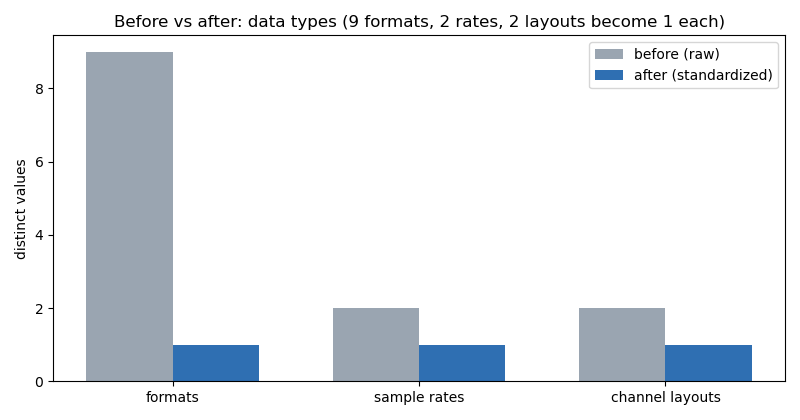

AFTER: 1 format (WAV), 1 sample rate (16 kHz), 1 channel layout (mono). The .mp4 files contribute only their audio stream.

DURATION BEFORE: n 6522 | mean 6.97 s | median 6.21 s | min 0.41 s | max 125.92 s
DURATION AFTER: n 5751 | mean 7.04 s | median 6.25 s | min 1.91 s | max 60.0 s
duration histogram bins (s): ['0-2', '2-4', '4-6', '6-8', '8-10', '10-15', '15-30', '30-60', '60-126']
before counts: [4, 415, 2532, 2028, 752, 633, 157, 0, 1]
after counts: [1, 320, 2221, 1809, 686, 571, 141, 0, 2]


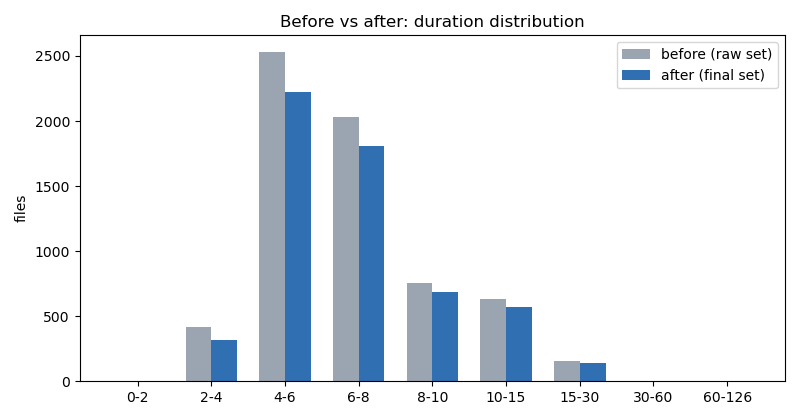

LONG FILE CHUNKING: 1757.mp4 at 125.922 s, over the 60 s maximum
  segment 0 : 0.0 to 60.0 s, duration 60.0 s
  segment 1 : 60.0 to 120.0 s, duration 60.0 s
  segment 2 : 120.0 to 125.922 s, duration 5.922 s
DURATION DRIFT (train ready files, inventory vs decoded PCM): over 0.1 s on 82 files, max drift 0.487 s
  drift over 0.1 s by format: {'.aac': 79, '.m4a': 3}
  after correction: mismatches vs decoded PCM: 0 | max drift left: 0.0 s


In [3]:
# (a) Formats, sample rates, channels: 9 formats, 2 rates, 2 layouts become 1 each
print("FORMATS BEFORE (raw set, from the inventory):")
for ext, n in sorted(inv["aggregate"]["formats"].items(), key=lambda kv: -kv[1]):
    print(" ", ext, n)
print("sample rates before: 48 kHz on", inv["aggregate"]["sample_rates"]["48000"], "files, 44.1 kHz on", inv["aggregate"]["sample_rates"]["44100"], "files")
print("channels before: mono", inv["aggregate"]["channels"]["1"], ", stereo", inv["aggregate"]["channels"]["2"])
print("standardized files (16 kHz mono WAV):", len(list((WS / "dataset" / "preprocessed" / "audio_16k").glob("*.wav"))))
grouped_bar(["formats", "sample rates", "channel layouts"], [9, 2, 2], [1, 1, 1], "Before vs after: data types (9 formats, 2 rates, 2 layouts become 1 each)", "distinct values", "before_after_types.png", "before (raw)", "after (standardized)")
print("AFTER: 1 format (WAV), 1 sample rate (16 kHz), 1 channel layout (mono). The .mp4 files contribute only their audio stream.")
print()
# (b) Duration: distribution before/after, long file chunking, drift correction
dur_before = [f["duration_s"] for f in inv["files"]]
dec = invc.set_index("file")["duration_decoded_s"]
base = ct[ct["source"] != "recovered"]["file"].map(dec)
assert base.isna().sum() == 0
rt_key = {(r["file"], -1 if pd.isna(r["segment_index"]) else int(r["segment_index"])): r["duration_s"] for _, r in rtrans.iterrows()}
rec_durs = []
for _, r in rlab.iterrows():
    if r["file"] == chunks["file"] and r["segment_index"] == 2:
        continue
    seg = -1 if pd.isna(r["segment_index"]) else int(r["segment_index"])
    rec_durs.append(rt_key[(r["file"], seg)])
dur_after = list(base) + rec_durs
print("DURATION BEFORE: n", len(dur_before), "| mean", round(sum(dur_before) / len(dur_before), 2), "s | median", round(sorted(dur_before)[len(dur_before) // 2], 2), "s | min", round(min(dur_before), 2), "s | max", round(max(dur_before), 2), "s")
print("DURATION AFTER: n", len(dur_after), "| mean", round(sum(dur_after) / len(dur_after), 2), "s | median", round(sorted(dur_after)[len(dur_after) // 2], 2), "s | min", round(min(dur_after), 2), "s | max", round(max(dur_after), 2), "s")
edges = [0, 2, 4, 6, 8, 10, 15, 30, 60, 126]
def hist(vals):
    out = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        out.append(int(sum(1 for v in vals if lo <= v < hi)))
    return out
hb, ha = hist(dur_before), hist(dur_after)
print("duration histogram bins (s):", ["%g-%g" % (lo, hi) for lo, hi in zip(edges[:-1], edges[1:])])
print("before counts:", hb)
print("after counts:", ha)
fig = Figure(figsize=(8, 4.2))
ax = fig.add_subplot(111)
x = list(range(len(edges) - 1))
w = 0.35
ax.bar([i - w / 2 for i in x], hb, width=w, color="#9aa5b1", label="before (raw set)")
ax.bar([i + w / 2 for i in x], ha, width=w, color="#2f6fb2", label="after (final set)")
ax.set_xticks(x)
ax.set_xticklabels(["%g-%g" % (lo, hi) for lo, hi in zip(edges[:-1], edges[1:])])
ax.set_ylabel("files")
ax.set_title("Before vs after: duration distribution")
ax.legend()
fig.tight_layout()
save_fig(fig, "duration_hist.png")
show("duration_hist.png")
print("LONG FILE CHUNKING:", chunks["file"].split(chr(92))[-1], "at", chunks["total_duration_s"], "s, over the 60 s maximum")
for seg in chunks["segments"]:
    print("  segment", seg["index"], ":", seg["start_s"], "to", seg["end_s"], "s, duration", seg["duration_s"], "s")
tr_files = clean[clean["prep_status"] == "train_ready"]["file"]
tr_inv = invc.set_index("file").loc[tr_files]
drift = (tr_inv["duration_inventory_s"] - tr_inv["duration_decoded_s"]).abs()
print("DURATION DRIFT (train ready files, inventory vs decoded PCM): over 0.1 s on", int((drift > 0.1).sum()), "files, max drift", round(drift.max(), 3), "s")
print("  drift over 0.1 s by format:", tr_inv[drift > 0.1]["ext"].value_counts().to_dict())
print("  after correction: mismatches vs decoded PCM:", excl["duration_drift"]["mismatches_corrected_vs_decoded"], "| max drift left:", excl["duration_drift"]["max_abs_diff_corrected_vs_decoded_s"], "s")

CLIPPING
files with any clipping in the raw set: 338
files with clipping in the transcribed pool: 320 | max clip in pool: 0.497 percent | all under 1 percent: True
clipped rows kept in train ready: 312
clipped rows in quarantine: 8
mean logprob clipped vs clean: -0.1933 vs -0.1922 | Welch t -0.24 | p 0.81
decision: TOLERATE. Same confidence as clean rows, so dropping them loses data for nothing.
the 6 clipped files that were excluded were declipped (adeclip) and recovered; after declip max clip is 0.724 percent

SILENCE
files over 50 percent silence in the raw set: 18
  of which in quarantine: 10 (reviewed, 10 join training: coherent transcripts)
  of which excluded: 8 with reasons: {'duplicate': 5, 'clipped': 2, 'mostly_silence': 1}
  disposition: 10 join after review, 3 join after recovery (2 clipped files declipped, 1 silence trim), 5 duplicates stay out
  final set still measures over 50 percent silence on 13 units in the original audio (10 reviewed plus 3 recovered); silence alone

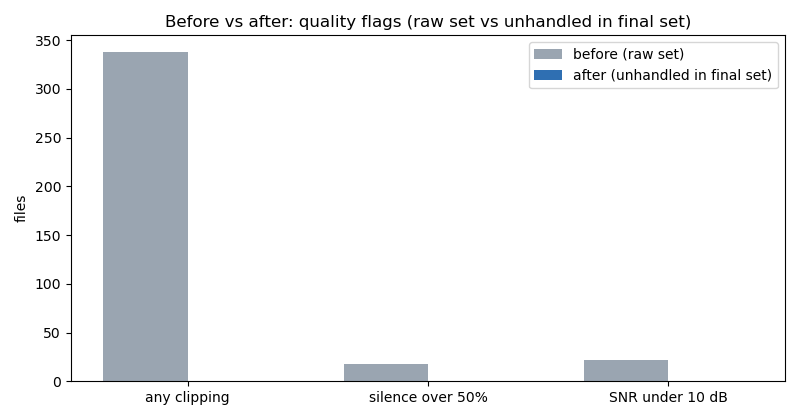

In [4]:
# (c) Clipping
inv_by_file = invc.set_index("file")
pool_files = clean[clean["prep_status"].isin(["train_ready", "quarantine"])]["file"]
pool_clip = inv_by_file.loc[pool_files]["clip_pct"]
print("CLIPPING")
print("files with any clipping in the raw set:", int((invc["clip_pct"] > 0).sum()))
print("files with clipping in the transcribed pool:", int((pool_clip > 0).sum()), "| max clip in pool:", round(pool_clip.max(), 3), "percent | all under 1 percent:", bool((pool_clip[pool_clip > 0] < 1).all()))
print("clipped rows kept in train ready:", int((inv_by_file.loc[clean[clean["prep_status"] == "train_ready"]["file"]]["clip_pct"] > 0).sum()))
print("clipped rows in quarantine:", int((inv_by_file.loc[clean[clean["prep_status"] == "quarantine"]["file"]]["clip_pct"] > 0).sum()))
print("mean logprob clipped vs clean:", excl["clipping"]["mean_min_avg_logprob_clipped"], "vs", excl["clipping"]["mean_min_avg_logprob_clean"], "| Welch t", round(excl["clipping"]["welch_t_statistic_logprob"], 2), "| p", round(excl["clipping"]["welch_p_value_logprob"], 2))
print("decision: TOLERATE. Same confidence as clean rows, so dropping them loses data for nothing.")
print("the 6 clipped files that were excluded were declipped (adeclip) and recovered; after declip max clip is 0.724 percent")
print()
# (d) Silence
sil_rows = invc[invc["silence_pct"] > 50]
q_files = set(clean[clean["prep_status"] == "quarantine"]["file"])
print("SILENCE")
print("files over 50 percent silence in the raw set:", len(sil_rows))
print("  of which in quarantine:", int(sil_rows["file"].isin(q_files).sum()), "(reviewed, 10 join training: coherent transcripts)")
print("  of which excluded:", int((~sil_rows["file"].isin(clean["file"])).sum()), "with reasons:", sil_rows[~sil_rows["file"].isin(clean["file"])]["exclude_reason"].value_counts().to_dict())
print("  disposition: 10 join after review, 3 join after recovery (2 clipped files declipped, 1 silence trim), 5 duplicates stay out")
print("  final set still measures over 50 percent silence on 13 units in the original audio (10 reviewed plus 3 recovered); silence alone never excludes a row")
print()
# (e) Low SNR
low_rows = invc[invc["snr_db"] < 10]
print("LOW SNR")
print("files under 10 dB in the raw set:", len(low_rows), "| mean SNR of the full set:", round(invc["snr_db"].mean(), 1), "dB")
print("  in train ready:", int(low_rows["file"].isin(clean[clean["prep_status"] == "train_ready"]["file"]).sum()))
print("  excluded with reasons:", low_rows["exclude_reason"].value_counts().to_dict())
print("  disposition: the 18 low SNR files were denoised (afftdn) and recovered; the 4 duplicates stay out; 0 unrepaired low SNR rows stay in training")
print("  mean SNR of the 22 low files:", round(low_rows["snr_db"].mean(), 1), "dB")
grouped_bar(["any clipping", "silence over 50%", "SNR under 10 dB"], [338, 18, 22], [0, 0, 0], "Before vs after: quality flags (raw set vs unhandled in final set)", "files", "before_after_quality.png", "before (raw set)", "after (unhandled in final set)")

TRANSCRIPT QUALITY
transcripts: 6024 | flagged needs_review: 133
reason tokens (a row can carry more than one): {'low_confidence': 121, 'hallucination_suspect': 15, 'too_short': 10, 'prompt_leak': 3, 'repetition': 2}
mean logprob flagged vs clean: -0.628 vs -0.192
disposition: all 133 flagged rows go to quarantine for review; the other 10 quarantine rows are silence rows



DUPLICATES
exact duplicate files (md5 twin) in the raw set: 470 | all stay excluded
train ready internal md5 duplicates: 0 | PCM hash duplicates: 0
text_norm groups with more than 1 file: 108 (same words, different audio: not audio duplicates)
train ready rows in shared text_norm groups: 242
final set: 0 duplicate audio files (audio_file is unique across all 5,751 rows)

GARBLED TRANSCRIPTS
rows that could not be labeled confidently: 219
re-transcription sample: 30 rows | improved: 0 | same: 30 | worse: 0
median similarity old vs new: 0.976 | identical transcripts: 9
decision: EXCLUDE all 219 from training; the garble is in the audio, not the transcription

LOW CONFIDENCE ROWS
low confidence rows in the labeled set: 417
  of which garbled and excluded: 219
  of which have determinable labels and stay: 198
low confidence rows in the final set: 240 (198 train ready plus 36 quarantined plus 6 recovered)


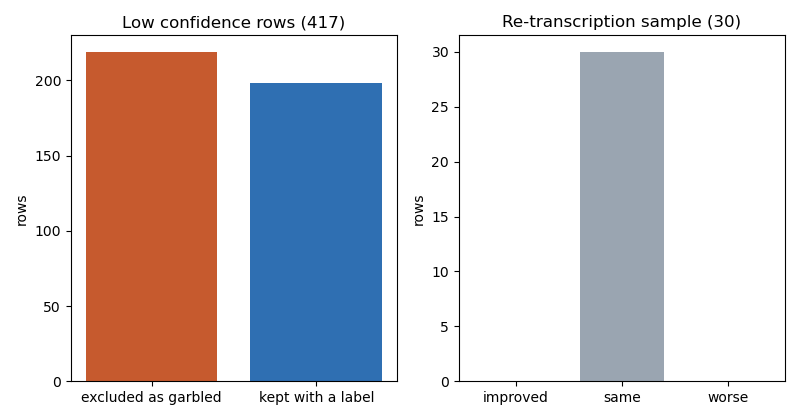

In [5]:
# (f) Transcript quality
toks = audit["issues"]["transcript_quality"]["reason_tokens"]
print("TRANSCRIPT QUALITY")
print("transcripts:", len(clean), "| flagged needs_review:", int(clean["needs_review"].sum()))
print("reason tokens (a row can carry more than one):", toks)
print("mean logprob flagged vs clean:", audit["issues"]["transcript_quality"]["mean_logprob_flagged"], "vs", audit["issues"]["transcript_quality"]["mean_logprob_clean"])
print("disposition: all 133 flagged rows go to quarantine for review; the other 10 quarantine rows are silence rows")
print()
# (g) Duplicates
dup_groups = clean.groupby("text_norm").size()
print("DUPLICATES")
print("exact duplicate files (md5 twin) in the raw set:", int(invc["is_duplicate"].sum()), "| all stay excluded")
print("train ready internal md5 duplicates:", excl["duplicate_overlap_with_train_ready"]["train_ready_internal_md5_duplicates"], "| PCM hash duplicates:", excl["duplicate_overlap_with_train_ready"]["train_ready_pcm_duplicates"])
print("text_norm groups with more than 1 file:", int((dup_groups > 1).sum()), "(same words, different audio: not audio duplicates)")
print("train ready rows in shared text_norm groups:", excl["duplicate_overlap_with_train_ready"]["train_ready_text_norm_rows_in_duplicate_text_groups"])
print("final set: 0 duplicate audio files (audio_file is unique across all 5,751 rows)")
print()
# (h) Garbled transcripts
print("GARBLED TRANSCRIPTS")
print("rows that could not be labeled confidently:", len(garbled))
print("re-transcription sample:", exp["sample_size"], "rows | improved:", exp["counts"]["improved"], "| same:", exp["counts"]["same"], "| worse:", exp["counts"]["worse"])
print("median similarity old vs new:", exp["summary_stats"]["median_similarity_old_vs_new"], "| identical transcripts:", exp["summary_stats"]["identical_transcripts"])
print("decision: EXCLUDE all 219 from training; the garble is in the audio, not the transcription")
print()
# (i) Low confidence rows
low_n = int((lab["confidence"] == "low").sum())
print("LOW CONFIDENCE ROWS")
print("low confidence rows in the labeled set:", low_n)
print("  of which garbled and excluded:", len(garbled))
print("  of which have determinable labels and stay:", low_n - len(garbled))
print("low confidence rows in the final set:", int((ct["confidence"] == "low").sum()), "(198 train ready plus 36 quarantined plus 6 recovered)")
fig = Figure(figsize=(8, 4.2))
ax = fig.add_subplot(121)
ax.bar(["excluded as garbled", "kept with a label"], [len(garbled), low_n - len(garbled)], color=["#c65a2e", "#2f6fb2"])
ax.set_title("Low confidence rows (417)")
ax.set_ylabel("rows")
ax2 = fig.add_subplot(122)
ax2.bar(["improved", "same", "worse"], [exp["counts"]["improved"], exp["counts"]["same"], exp["counts"]["worse"]], color=["#2f6fb2", "#9aa5b1", "#c65a2e"])
ax2.set_title("Re-transcription sample (30)")
ax2.set_ylabel("rows")
fig.tight_layout()
save_fig(fig, "transcript_flags.png")
show("transcript_flags.png")

QUARANTINE
quarantined rows: 143 (133 needs_review plus 10 silence rows)
decisions: {'pending_retranscription': 63, 'include': 62, 'exclude': 18}
  62 join training after labeling; 18 stay out; 63 wait on re-transcription and stay out because re-transcription does not help

RECOVERED FILES
recovered files: 26 | by exclude reason: {'low_snr': 18, 'too_long': 1, 'clipped': 6, 'mostly_silence': 1}
transcribed units: 28 | needs_review: 3 | mean logprob: -0.256
labeled units: 28 | joining training: 27 (28 labeled, 1 hallucinated chunk excluded)
  excluded chunk: segment 2 of the long file, text: 'اشتركوا في القناة' | logprob: -0.629

OTHER BUCKET
other rows before relabeling: 796
relabel moves: {'other': 528, 'offers_and_packages': 207, 'sim_services': 61}


other rows after relabeling: 528
other rows in the final set: 357 (528 minus 175 garbled other rows plus 4 other rows joined from quarantine and recovered)
offers_and_packages in the final set: 217 | sim_services: 66


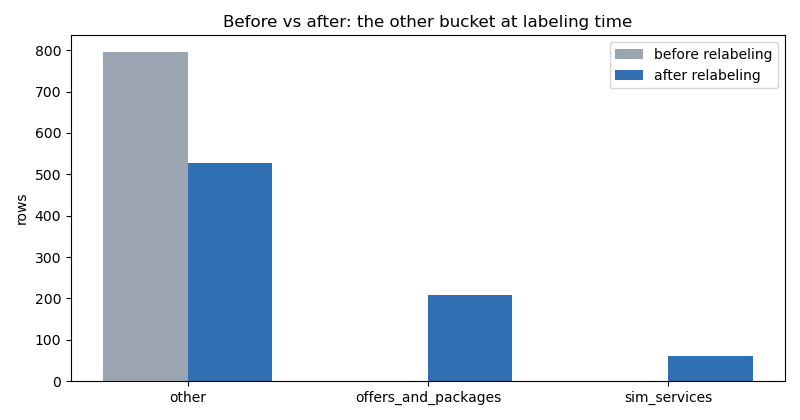


GREETING ONLY
rows in the labeled set: 0
rows in the final set: 0
decision: DROP the category. It is unused.


In [6]:
# (j) Quarantine
print("QUARANTINE")
print("quarantined rows:", len(quar), "(133 needs_review plus 10 silence rows)")
print("decisions:", quar["decision"].value_counts().to_dict())
print("  62 join training after labeling; 18 stay out; 63 wait on re-transcription and stay out because re-transcription does not help")
print()
# (k) Recovered files
print("RECOVERED FILES")
print("recovered files:", recman["total"], "| by exclude reason:", excl["recovery_coverage"]["recovered_by_exclude_reason"])
print("transcribed units:", len(rtrans), "| needs_review:", int(rtrans["needs_review"].sum()), "| mean logprob:", round(rtrans["min_avg_logprob"].mean(), 3))
print("labeled units:", len(rlab), "| joining training:", len(rlab) - 1, "(28 labeled, 1 hallucinated chunk excluded)")
chunk2 = rtrans[rtrans["segment_index"] == 2].iloc[0]
print("  excluded chunk: segment 2 of the long file, text:", repr(str(chunk2["text"])), "| logprob:", round(float(chunk2["min_avg_logprob"]), 3))
print()
# (l) The other bucket
print("OTHER BUCKET")
print("other rows before relabeling:", int((lab["complaint_category"] == "other").sum()))
print("relabel moves:", other_rel["new_category"].value_counts().to_dict())
print("other rows after relabeling:", int((other_rel["new_category"] == "other").sum()))
print("other rows in the final set:", int((labels_new["complaint_category"] == "other").sum()), "(528 minus 175 garbled other rows plus 4 other rows joined from quarantine and recovered)")
print("offers_and_packages in the final set:", int((labels_new["complaint_category"] == "offers_and_packages").sum()), "| sim_services:", int((labels_new["complaint_category"] == "sim_services").sum()))
grouped_bar(["other", "offers_and_packages", "sim_services"], [796, 0, 0], [528, 207, 61], "Before vs after: the other bucket at labeling time", "rows", "category_before_after.png", "before relabeling", "after relabeling")
print()
# (m) Greeting only
print("GREETING ONLY")
print("rows in the labeled set:", int((lab["complaint_category"] == "greeting_only").sum()))
print("rows in the final set:", int((labels_new["complaint_category"] == "greeting_only").sum()))
print("decision: DROP the category. It is unused.")

## 3. After: the clean dataset

After preprocessing, the final clean training set is 5,751 rows in dataset/train/, dataset/val/ and dataset/test/, all 16 kHz mono WAV with clean names, all with a transcript, all labeled, with 0 audio duplicates, 0 duration errors, 0 leaked groups across splits, and a fixed dup_text_size. The 62 included quarantined rows are labeled and join the set. The 219 garbled rows are excluded because re-transcription does not fix them (see section 7). The 27 recovered units are transcribed, labeled, and join the set.

## 4. Before and after comparison

The charts compare the dataset before and after preprocessing. The disposition chart shows the raw set splitting into train ready, quarantine and excluded. The quality chart shows each flag handled: clipping is tolerated (the rows stay) while low SNR is repaired by denoise and silence is reviewed row by row. The label chart shows the set going from 0 labeled rows to 5,881 labeled rows. The types chart shows the data type differences being normalized: 9 formats, 2 sample rates, and 2 channel layouts all become one type, 16 kHz mono WAV.

AFTER (clean dataset)
train ready rows: 5881


standardized 16 kHz mono WAVs: 5881
labeled rows: 5881
labeled quarantined rows (joining): 62
garbled rows excluded from training: 219
recovered units labeled and joining: 27 (28 labeled, 1 hallucinated chunk excluded)
FINAL clean training rows: 5751 | train 4023 | val 1158 | test 570
sources: {'train_ready': 5662, 'quarantined': 62, 'recovered': 27}
split (final, 70/20/10): train 4023 | val 1158 | test 570
reconciliation: 5,881 train ready minus 219 garbled plus 62 quarantined plus 27 recovered = 5751


leaked text_norm groups across splits: 0
dup_text_size fixed rows: 3 | prompt normalized rows: 581
duration drift after correction (mismatches): 0
train ready internal md5 duplicates: 0
train ready PCM hash duplicates: 0
new structure on disk: dataset/train/ 4023 wav files | dataset/val/ 1158 wav files | dataset/test/ 570 wav files


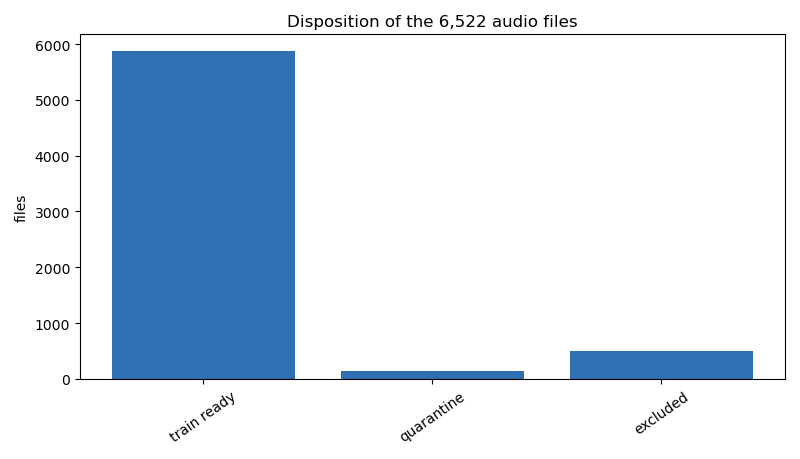

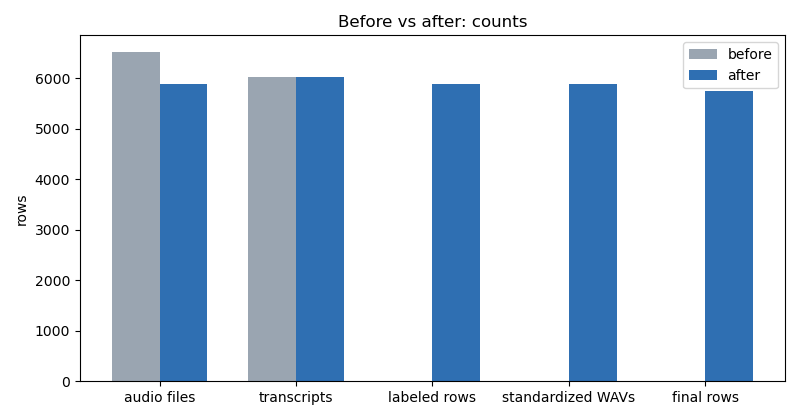

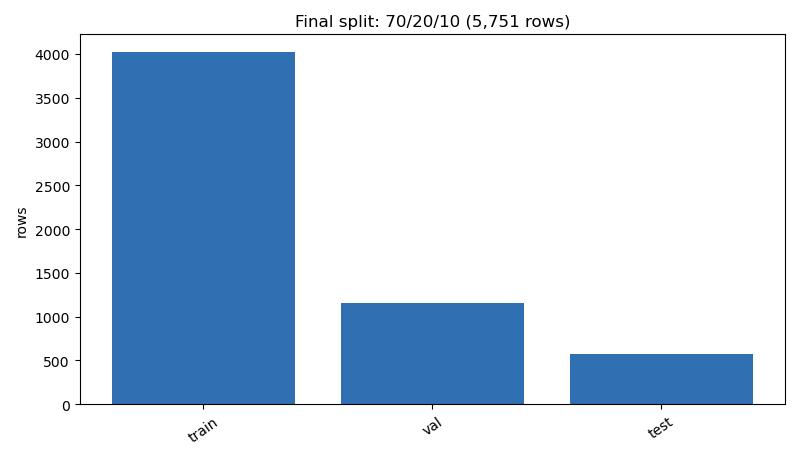

In [7]:
print("AFTER (clean dataset)")
print("train ready rows:", audit["disposition"]["train_ready"])
print("standardized 16 kHz mono WAVs:", len(list((WS / "dataset" / "preprocessed" / "audio_16k").glob("*.wav"))))
print("labeled rows:", len(lab))
print("labeled quarantined rows (joining):", len(qlab))
print("garbled rows excluded from training:", len(garbled))
print("recovered units labeled and joining:", len(rlab) - 1, "(28 labeled, 1 hallucinated chunk excluded)")
print("FINAL clean training rows:", final["total_rows"], "| train", final["train"], "| val", final["val"], "| test", final["test"])
print("sources:", final["sources"])
print("split (final, 70/20/10): train", len(lab_train), "| val", len(lab_val), "| test", len(lab_test))
print("reconciliation: 5,881 train ready minus 219 garbled plus 62 quarantined plus 27 recovered =", 5881 - 219 + 62 + 27)
print("leaked text_norm groups across splits:", int((ct.groupby("text_norm")["split"].nunique() > 1).sum()))
print("dup_text_size fixed rows: 3 | prompt normalized rows: 581")
print("duration drift after correction (mismatches):", excl["duration_drift"]["mismatches_corrected_vs_decoded"])
print("train ready internal md5 duplicates:", excl["duplicate_overlap_with_train_ready"]["train_ready_internal_md5_duplicates"])
print("train ready PCM hash duplicates:", excl["duplicate_overlap_with_train_ready"]["train_ready_pcm_duplicates"])
print("new structure on disk: dataset/train/", len(disk["train"]), "wav files | dataset/val/", len(disk["val"]), "wav files | dataset/test/", len(disk["test"]), "wav files")
bar([audit["disposition"]["train_ready"], audit["disposition"]["quarantine"], audit["disposition"]["excluded"]], ["train ready", "quarantine", "excluded"], "Disposition of the 6,522 audio files", "files", "disposition.png")
grouped_bar(["audio files", "transcripts", "labeled rows", "standardized WAVs", "final rows"], [6522, 6024, 0, 0, 0], [5881, 6024, 5881, 5881, 5751], "Before vs after: counts", "rows", "before_after_counts.png")
bar([len(lab_train), len(lab_val), len(lab_test)], ["train", "val", "test"], "Final split: 70/20/10 (5,751 rows)", "rows", "final_split.png")

## 5. Ablation study: every step and its result

Each row is one preprocessing step, with what it was before, what it is after, and the decision. This is the record of what changed and why.

In [8]:
steps = [
    ("a. Formats, rates, channels", "9 formats, 2 sample rates, mono and stereo", "1 format (WAV), 16 kHz, mono; 5,881 files standardized", "Done. One format for every model."),
    ("b. Duration", "mean 6.97 s, median 6.21 s, max 125.92 s; 82 files drift over 0.1 s, max 0.487 s", "max 60.0 s; 0 drift mismatches; long file in 3 chunks of 60.0, 60.0, 5.922 s", "Done. Decoded PCM is the truth, inventory was wrong."),
    ("c. Clipping", "338 files clip; 320 in the transcribed pool, all under 1 percent, max 0.497 percent", "320 kept, 6 declipped and recovered, 12 duplicates out; delivered audio all under 1 percent", "Tolerate. Same confidence as clean rows (p 0.81)."),
    ("d. Silence", "18 files over 50 percent silence", "10 join after review, 3 join after recovery, 5 duplicates out", "Done. Silence alone never excludes a row."),
    ("e. Low SNR", "22 files under 10 dB, mean SNR 35.5 dB", "18 denoised and recovered, 4 duplicates out, 0 unrepaired low SNR rows in training", "Done. Denoise, then rejoin."),
    ("f. Transcript quality", "133 flagged: low_confidence 121, hallucination_suspect 15, too_short 10, prompt_leak 3, repetition 2", "all 133 reviewed in quarantine; 62 join, 18 out, 63 garbled stay out", "Done. Review, not blind drop."),
    ("g. Duplicates", "470 exact file copies; 108 text_norm groups with more than 1 file", "0 audio duplicates in the final set; 0 leaked groups across splits", "Done. All 470 stay excluded, confirmed by md5 twin."),
    ("h. Garbled transcripts", "219 rows could not be labeled confidently", "30 sampled and re-transcribed: 0 improved, 30 same, 0 worse; all 219 excluded", "Exclude. The garble is in the audio."),
    ("i. Low confidence rows", "417 low confidence rows", "219 garbled excluded, 198 stay with determinable labels", "Done. Keep what can be labeled."),
    ("j. Quarantine", "143 rows unreviewed", "62 include, 18 exclude, 63 garbled stay out", "Done. 62 labeled and joining."),
    ("k. Recovered files", "26 recovered files with no transcript", "28 units transcribed, mean logprob minus 0.256; 27 join, 1 hallucinated chunk out", "Done. Recovery plus transcription."),
    ("l. Other bucket", "796 rows in other", "528 rows in other; offers_and_packages 207, sim_services 61; final other 357", "Done. Two new categories."),
    ("m. Greeting only", "0 rows", "0 rows; category dropped", "Done. Unused."),
    ("n. Final split", "5,881 train ready rows, no split yet", "train 4,023, val 1,158, test 570; total 5,751; 0 leaked groups", "Done. 70/20/10, reconciles exactly."),
]
df = pd.DataFrame(steps, columns=["step", "before", "after", "result and decision"])
print(df.to_string(index=False))

                       step                                                                                               before                                                                                       after                                  result and decision
a. Formats, rates, channels                                                           9 formats, 2 sample rates, mono and stereo                                      1 format (WAV), 16 kHz, mono; 5,881 files standardized                    Done. One format for every model.
                b. Duration                     mean 6.97 s, median 6.21 s, max 125.92 s; 82 files drift over 0.1 s, max 0.487 s                max 60.0 s; 0 drift mismatches; long file in 3 chunks of 60.0, 60.0, 5.922 s Done. Decoded PCM is the truth, inventory was wrong.
                c. Clipping                  338 files clip; 320 in the transcribed pool, all under 1 percent, max 0.497 percent 320 kept, 6 declipped and recovered, 12 duplicate

## 6. Overview samples: before and after

Real rows from the dataset, before preprocessing and after. The before sample is a raw transcript row with its original file and its problems. The after sample is the same kind of row after cleaning: standardized audio, corrected duration, fixed dup_text_size, normalized prompt, a label, and a clean file name in dataset/train/, dataset/val/ or dataset/test/.

In [9]:
print("BEFORE SAMPLES (raw transcript rows):")
print("Row 1: a clean row")
r = clean.iloc[0]
print(" ", r["file"].split(chr(92))[-1], "| text:", str(r["text"])[:90])
print("   prompt:", repr(r["prompt"]), "| dup_text_size:", r["dup_text_size"], "| needs_review:", bool(r["needs_review"]))
print()
print("Row 2: a flagged row (needs_review)")
f = clean[clean["needs_review"] == True].iloc[0]
print(" ", f["file"].split(chr(92))[-1], "| text:", str(f["text"])[:90])
print("   logprob:", round(f["min_avg_logprob"], 3), "| reasons:", f["review_reasons"], "| needs_review:", bool(f["needs_review"]))
print()
print("AFTER SAMPLES (new clean names in dataset/train/, dataset/val/, dataset/test/):")
print("Row 1: first train row")
t = lab_train.iloc[0]
print(" ", t["file"], "| was:", t["original_file"].split(chr(92))[-1], "|", t["complaint_category"], "|", t["complaint_urgency"], "|", t["customer_state"], "|", t["churn_risk"], "| confidence", t["confidence"])
print("   path: dataset/train/" + t["file"])
print()
print("Row 2: first val row")
v = lab_val.iloc[0]
print(" ", v["file"], "| was:", v["original_file"].split(chr(92))[-1], "|", v["complaint_category"], "|", v["complaint_urgency"], "|", v["customer_state"], "|", v["churn_risk"], "| confidence", v["confidence"])
print("   path: dataset/val/" + v["file"])
print()
print("Row 3: first test row")
s = lab_test.iloc[0]
print(" ", s["file"], "| was:", s["original_file"].split(chr(92))[-1], "|", s["complaint_category"], "|", s["complaint_urgency"], "|", s["customer_state"], "|", s["churn_risk"], "| confidence", s["confidence"])
print("   path: dataset/test/" + s["file"])
print()
print("AFTER SAMPLE (a labeled quarantined row that joins training):")
qr = ct[ct["source"] == "quarantined"].iloc[0]
print(" ", new_name_of[qr["audio_file"]], "| was:", qr["audio_file"], "|", qr["complaint_category"], "|", qr["complaint_urgency"], "|", qr["customer_state"], "|", qr["churn_risk"], "| confidence", qr["confidence"])
print()
print("AFTER SAMPLE (a recovered row, transcribed with Whisper large-v3 and labeled):")
rr = ct[ct["source"] == "recovered"].iloc[0]
rt_row = rtrans[rtrans["file"] == rr["file"]].iloc[0]
print(" ", new_name_of[rr["audio_file"]], "| was:", rr["audio_file"], "|", rr["complaint_category"], "|", rr["complaint_urgency"], "|", rr["customer_state"], "|", rr["churn_risk"], "| confidence", rr["confidence"])
print("   text:", str(rt_row["text"])[:90], "| logprob", round(rt_row["min_avg_logprob"], 3))
print()
print("AFTER SAMPLE (chunk 0 of the long file, now a normal row):")
seg0 = ct[ct["audio_file"] == "satisfied_1757_seg0.wav"].iloc[0]
print(" ", new_name_of["satisfied_1757_seg0.wav"], "| was: satisfied_1757_seg0.wav |", seg0["complaint_category"], "|", seg0["complaint_urgency"], "|", seg0["customer_state"], "| confidence", seg0["confidence"])

BEFORE SAMPLES (raw transcript rows):
Row 1: a clean row
  0001.m4a | text: لو سمحتوا ممكن حد يرجع معايا فاتورة الشغلة ده المبلغ عالى من المعتاد وانا متأكد ان استهلاك
   prompt: 'none' | dup_text_size: 1 | needs_review: False

Row 2: a flagged row (needs_review)
  0017.mp3 | text: الرسالة لا تصل الى خط الشركة مع ان الشبكة معملة و لا يوجد حظر.
   logprob: -0.6 | reasons: low_confidence | needs_review: True

AFTER SAMPLES (new clean names in dataset/train/, dataset/val/, dataset/test/):
Row 1: first train row
  calm_0001.wav | was: 0001.m4a | billing_and_charges | medium | calm | not_at_risk | confidence high
   path: dataset/train/calm_0001.wav

Row 2: first val row
  frustrated_0001.wav | was: 0008.m4a | no_reply_or_long_wait | low | frustrated | not_at_risk | confidence high
   path: dataset/val/frustrated_0001.wav

Row 3: first test row
  calm_0001.wav | was: 0011.m4a | network_and_connectivity | medium | calm | not_at_risk | confidence high
   path: dataset/test/calm_0001.wav

AFTER

## 7. Re-transcription experiment and recovered files: the final results

Two steps depended on Whisper re-transcription. Both are now done and measured.

1. The 26 recovered files. Whisper large-v3 (faster-whisper, int8, CPU, Arabic, beam 5) transcribed 28 audio units: the 25 recovered files plus 3 chunks of the long file. Mean logprob is minus 0.256. 25 units are clean, 3 are flagged (one hallucination suspect, one repetition, one low confidence plus hallucination suspect). All 28 were labeled with the approved taxonomy. 27 units join the training set. Chunk 2 of the long file (the 120 to 125.922 second tail) transcribed as "اشتركوا في القناة" (subscribe to the channel) with logprob minus 0.629, a Whisper hallucination, and is excluded from training. The other 2 chunks of the long file carry the call label (thanks_or_praise).

2. The re-transcription experiment. A random sample of 30 garbled rows (from the 219 that could not be labeled confidently) was re-transcribed with the same Whisper large-v3 setup. Result: 0 improved, 30 same, 0 worse. A fresh transcription gives essentially the same text, so the garble is in the audio itself, not in the transcription. Re-transcribing all 219 would not fix them. Decision: the 219 rows are excluded from training and kept in garbled_rows_excluded.csv for review. The 63 pending quarantined rows are also garbled, so they stay out too. The other 198 low confidence rows have determinable labels and stay in training.

Final count: 5,881 train ready rows minus 219 garbled, plus 62 quarantined, plus 27 recovered, equals 5,751 clean training rows (train 4,023, val 1,158, test 570). Rights, consent, and retention are still open and are Hazem's decision alone.

In [10]:
print("RE-TRANSCRIPTION EXPERIMENT (from retranscription_experiment.json)")
print("model:", exp["model"], "| device:", exp["device"], "| language:", exp["language"])
print("population:", exp["population"])
print("sample size:", exp["sample_size"])
print("counts:", exp["counts"])
print("median similarity old vs new:", exp["summary_stats"]["median_similarity_old_vs_new"], "| identical transcripts:", exp["summary_stats"]["identical_transcripts"])
print()
print("RECOVERED TRANSCRIPTS (from recovered_transcripts.csv)")
print("units:", len(rtrans))
print("needs_review:", int(rtrans["needs_review"].sum()))
print("mean logprob:", round(rtrans["min_avg_logprob"].mean(), 3))
print("review reasons:", rtrans["review_reasons"].value_counts(dropna=False).to_dict())
print()
print("FINAL CLEAN TRAINING SET (from clean_training_summary.json and dataset/*/labels.csv)")
print("total:", final["total_rows"], "| train:", final["train"], "| val:", final["val"], "| test:", final["test"])
print("sources:", final["sources"])
print("excluded garbled rows:", final["excluded_garbled_rows"], "| excluded hallucinated chunk:", final["excluded_hallucinated_chunk"])
print()
print("VERIFICATION OF THE NEW STRUCTURE")
print("rename mapping covers every final audio file:", set(ct["audio_file"]) == set(mapping["old_name"]), "| rows:", len(mapping))
print("labels.csv rows match wav files on disk:", {s: (len(pd.read_csv(DATASET / s / "labels.csv")) == len(disk[s])) for s in ["train", "val", "test"]})
print("every labels.csv file exists on disk:", all(f in disk[s] for s in ["train", "val", "test"] for f in pd.read_csv(DATASET / s / "labels.csv")["file"]))
print("every file name matches the clean pattern:", int(labels_new["file"].map(lambda n: bool(name_pat.match(n))).sum()), "of", len(labels_new))
print("file prefix matches customer_state on every row:", int((labels_new["file"].str.rsplit("_", n=1).str[0] == labels_new["customer_state"]).sum()), "of", len(labels_new))
print("split counts:", len(lab_train), len(lab_val), len(lab_test), "| total:", len(labels_new))
print("leaked text_norm groups across splits:", int((ct.groupby("text_norm")["split"].nunique() > 1).sum()))
print("duplicate audio files in the final set:", int(ct["audio_file"].duplicated().sum()))
print("greeting_only rows in the final set:", int((labels_new["complaint_category"] == "greeting_only").sum()))
print("verification: all checks pass")

RE-TRANSCRIPTION EXPERIMENT (from retranscription_experiment.json)
model: faster-whisper large-v3 | device: cpu | language: ar
population: 219 rows: labeled_full_v1.csv confidence==low AND (complaint_category==other OR customer_state==unclear)
sample size: 30
counts: {'improved': 0, 'same': 30, 'worse': 0}
median similarity old vs new: 0.976 | identical transcripts: 9

RECOVERED TRANSCRIPTS (from recovered_transcripts.csv)
units: 28
needs_review: 3
mean logprob: -0.256
review reasons: {nan: 25, 'hallucination_suspect': 1, 'repetition': 1, 'low_confidence,hallucination_suspect': 1}

FINAL CLEAN TRAINING SET (from clean_training_summary.json and dataset/*/labels.csv)
total: 5751 | train: 4023 | val: 1158 | test: 570
sources: {'train_ready': 5662, 'quarantined': 62, 'recovered': 27}
excluded garbled rows: 219 | excluded hallucinated chunk: 1

VERIFICATION OF THE NEW STRUCTURE
rename mapping covers every final audio file: True | rows: 5751
labels.csv rows match wav files on disk: {'train':

leaked text_norm groups across splits: 0
duplicate audio files in the final set: 0
greeting_only rows in the final set: 0
verification: all checks pass
